<a href="https://colab.research.google.com/github/tahzibultamim/PythonProjects/blob/sM/clustering_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Load and Preprocess the Data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score
import scipy.cluster.hierarchy as sch

# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
# 2. Load dataset from Google Drive
df = pd.read_csv('/content/drive/MyDrive/datasets/sgdata.csv')

# Clean the data by handling missing values
print('Missing values count:')
print(df.isnull().sum())
df = df.dropna().reset_index(drop=True)

# Encode the Education Level (categorical feature)
education_mapping = {
    'other / unknown': 0,
    'high school': 1,
    'university': 2,
    'graduate school': 3
}
df['Education_Level'] = df['Education'].map(education_mapping)

# Standardize features (Age, Income, Education Level)
features = ['Age', 'Income', 'Education_Level']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Missing values count:
ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64


# 2. Apply K-Means Clustering

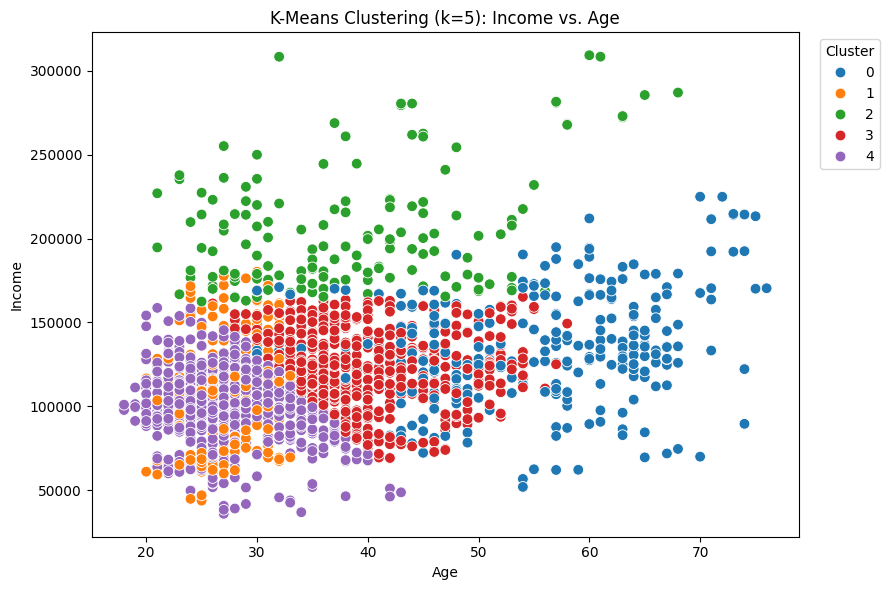

Characteristics of K-Means Clusters:
                Count   Age_Mean    Income_Mean Primary_Education
KMeans_Cluster                                                   
0                 295  54.708475  134525.511864        university
1                 271  27.372694  108636.933579   other / unknown
2                 156  38.897436  205392.621795       high school
3                 582  40.008591  122324.664948       high school
4                 696  27.166667   99926.722701       high school


In [6]:
# Segment into 5 clusters using K-Means
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Visualize clusters: scatter plot of Income vs. Age
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='Age',
    y='Income',
    hue='KMeans_Cluster',
    palette='tab10',
    s=60
)
plt.title('K-Means Clustering (k=5): Income vs. Age')
plt.xlabel('Age')
plt.ylabel('Income')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Characteristics of each cluster
cluster_characteristics = df.groupby('KMeans_Cluster').agg(
    Count=('ID', 'count'),
    Age_Mean=('Age', 'mean'),
    Income_Mean=('Income', 'mean'),
    Primary_Education=('Education', lambda x: x.mode()[0])
)
print('Characteristics of K-Means Clusters:')
print(cluster_characteristics)

# 3. Apply Hierarchical Clustering and Compare with K-Means

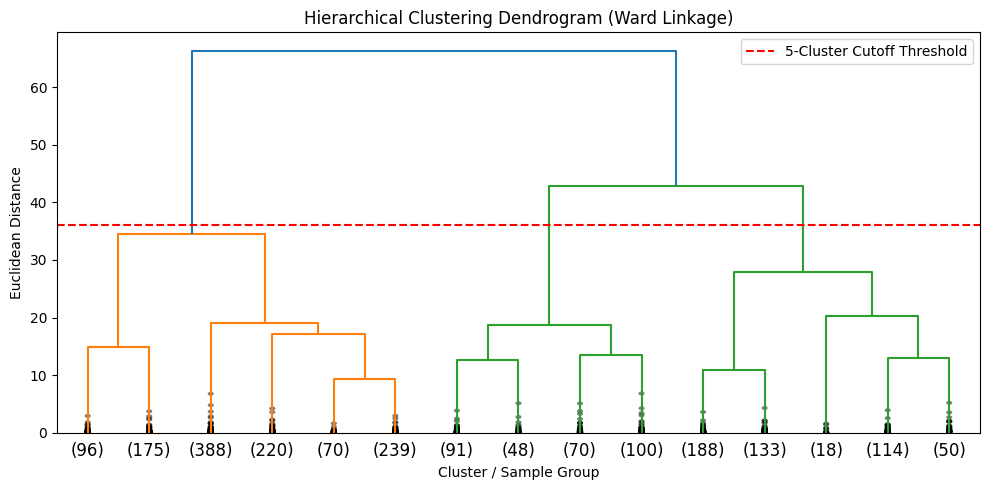

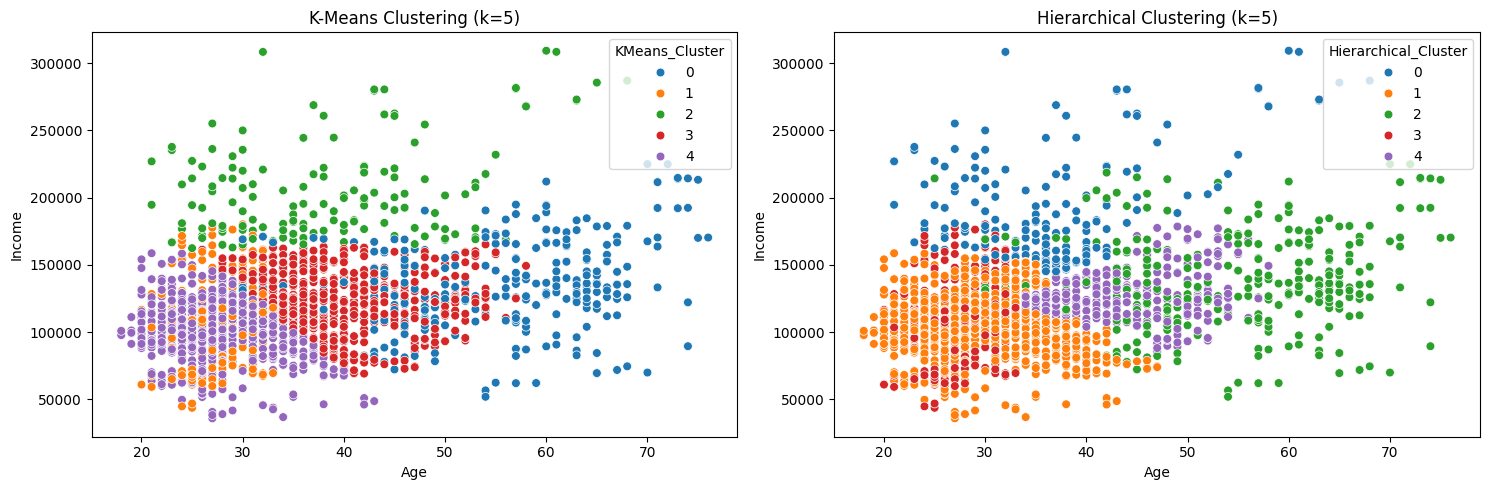

Adjusted Rand Index (ARI): 0.6588
K-Means Silhouette Score: 0.3649
Hierarchical Silhouette Score: 0.3407

Contingency Table (K-Means vs. Hierarchical):
 Hierarchical_Cluster    0    1    2    3    4
KMeans_Cluster                               
0                       0    0  295    0    0
1                       0    0    0  271    0
2                     129    0   14    0   13
3                      53  221    0    0  308
4                       0  696    0    0    0


In [7]:
# Visualize Dendrogram
plt.figure(figsize=(10, 5))
linkage_matrix = sch.linkage(X_scaled, method='ward')
sch.dendrogram(linkage_matrix, truncate_mode='lastp', p=15, show_contracted=True)
plt.axhline(y=36, color='red', linestyle='--', label='5-Cluster Cutoff Threshold')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Cluster / Sample Group')
plt.ylabel('Euclidean Distance')
plt.legend()
plt.tight_layout()
plt.show()

# Agglomerative Hierarchical Clustering (5 clusters)
hierarchical = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)

# Visual Comparison: K-Means vs. Hierarchical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=df, x='Age', y='Income', hue='KMeans_Cluster', palette='tab10', ax=ax1, s=40)
ax1.set_title('K-Means Clustering (k=5)')
ax1.set_xlabel('Age')
ax1.set_ylabel('Income')

sns.scatterplot(data=df, x='Age', y='Income', hue='Hierarchical_Cluster', palette='tab10', ax=ax2, s=40)
ax2.set_title('Hierarchical Clustering (k=5)')
ax2.set_xlabel('Age')
ax2.set_ylabel('Income')

plt.tight_layout()
plt.show()

# Compare Hierarchical Clustering results with K-Means
print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(df['KMeans_Cluster'], df['Hierarchical_Cluster']):.4f}")
print(f"K-Means Silhouette Score: {silhouette_score(X_scaled, df['KMeans_Cluster']):.4f}")
print(f"Hierarchical Silhouette Score: {silhouette_score(X_scaled, df['Hierarchical_Cluster']):.4f}")
print('\nContingency Table (K-Means vs. Hierarchical):\n', pd.crosstab(df['KMeans_Cluster'], df['Hierarchical_Cluster']))